In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
base = pd.read_csv('../data/incoming/train_base.csv', parse_dates=['date'])
holidays_events = pd.read_csv('../data/raw/holidays_events.csv', parse_dates=['date'])
oil = pd.read_csv('../data/raw/oil.csv', parse_dates=['date'])
stores = pd.read_csv('../data/raw/stores.csv')
transactions = pd.read_csv('../data/raw/transactions.csv', parse_dates=['date'])

### Таблица train_base

In [4]:
base.info()

<class 'pandas.DataFrame'>
RangeIndex: 1839024 entries, 0 to 1839023
Data columns (total 6 columns):
 #   Column       Dtype         
---  ------       -----         
 0   id           int64         
 1   date         datetime64[us]
 2   store_nbr    int64         
 3   family       str           
 4   sales        float64       
 5   onpromotion  int64         
dtypes: datetime64[us](1), float64(1), int64(3), str(1)
memory usage: 84.2 MB


In [5]:
base.describe(include='all')

,id,date,store_nbr,family,sales,onpromotion
count,1.839024e+06,1839024,1.839024e+06,1839024,1.839024e+06,1.839024e+06
unique,NaN,NaN,NaN,33,NaN,NaN
top,NaN,NaN,NaN,AUTOMOTIVE,NaN,NaN
freq,NaN,NaN,NaN,55728,NaN,NaN
mean,9.195115e+05,2014-06-01 10:53:01.395349,2.750000e+01,NaN,2.940279e+02,6.986853e-01
min,0.000000e+00,2013-01-01 00:00:00,1.000000e+00,NaN,0.000000e+00,0.000000e+00
25%,4.597558e+05,2013-09-15 18:00:00,1.400000e+01,NaN,0.000000e+00,0.000000e+00
50%,9.195115e+05,2014-06-01 12:00:00,2.750000e+01,NaN,5.000000e+00,0.000000e+00
75%,1.379267e+06,2015-02-15 06:00:00,4.100000e+01,NaN,1.560000e+02,0.000000e+00
max,1.839023e+06,2015-10-31 00:00:00,5.400000e+01,NaN,4.627100e+04,2.220000e+02


#### Проверка на пропуски

In [ ]:
missing_count = base.isnull().sum()
missing_count

id             0
date           0
store_nbr      0
family         0
sales          0
onpromotion    0
dtype: int64

: 

: 

: 

Пропусков в таблице train_base нет.

#### Проверка на дубликаты

Проверка на наличие полных дубликатов

In [25]:
base.duplicated().sum()

np.int64(0)

Проверка на наличие дубликатов по id 

In [26]:
base['id'].duplicated().sum()

np.int64(0)

Проверка на наличие дубликатов по составному ключу

In [32]:
base.duplicated(subset=['date', 'store_nbr', 'family']).sum()

np.int64(0)

#### Признак family

Проверка на наличие опечатков

In [31]:
sorted(base['family'].unique())

['AUTOMOTIVE',
 'BABY CARE',
 'BEAUTY',
 'BEVERAGES',
 'BOOKS',
 'BREAD/BAKERY',
 'CELEBRATION',
 'CLEANING',
 'DAIRY',
 'DELI',
 'EGGS',
 'FROZEN FOODS',
 'GROCERY I',
 'GROCERY II',
 'HARDWARE',
 'HOME AND KITCHEN I',
 'HOME AND KITCHEN II',
 'HOME APPLIANCES',
 'HOME CARE',
 'LADIESWEAR',
 'LAWN AND GARDEN',
 'LINGERIE',
 'LIQUOR,WINE,BEER',
 'MAGAZINES',
 'MEATS',
 'PERSONAL CARE',
 'PET SUPPLIES',
 'PLAYERS AND ELECTRONICS',
 'POULTRY',
 'PREPARED FOODS',
 'PRODUCE',
 'SCHOOL AND OFFICE SUPPLIES',
 'SEAFOOD']

Опечаток в признаке family нет.

#### Признак store_nbr

Все ли 54 магазина представлены в данных

In [34]:
base['store_nbr'].nunique()

54

В данных представлены все филиалы

##### Признак sales (целевая переменная)

Функция describe показала, что отрицательных значений в признаке нет.

Построим boxplot целевой переменной

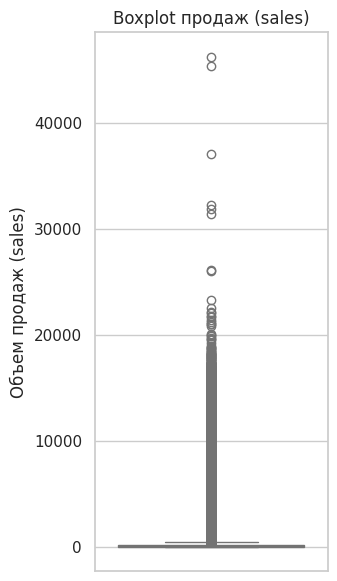

In [36]:
plt.figure(figsize=(3, 7))

sns.boxplot(y=base['sales'], data=base, color='lightgreen')

plt.title('Boxplot продаж (sales)')
plt.ylabel('Объем продаж (sales)')

plt.show()

Заметим, что целевая переменная содержит большое количество 0, поэтому сам ящик сплющен в 0.     
Из-за того, что большое количество значений содержит 0, нормальные значения также обозначены как выбросы на графике.      
Однако присутствуют действительно аномально большие значения, которые мы не будем удалять, так как это реальные покупки, которые могут быть объяснены праздником или важным событием.


Построим распределение целевой переменной

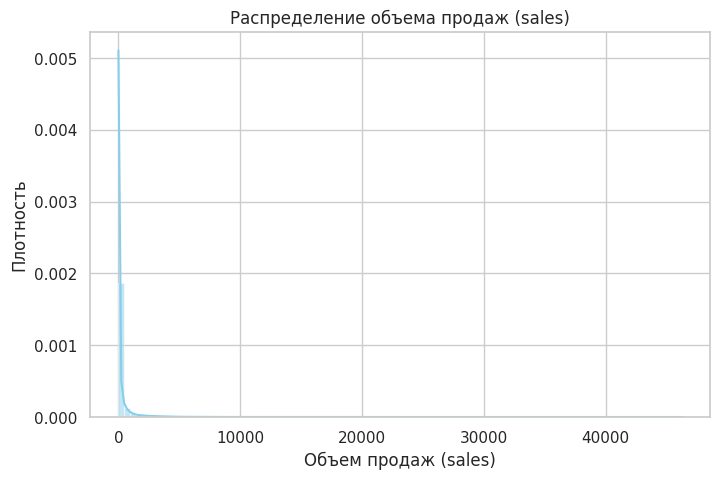

In [38]:
sns.set_theme(style="whitegrid")

plt.figure(figsize=(8, 5))

sns.histplot(base['sales'], kde=True, bins=100, color='skyblue', stat='density')

plt.title('Распределение объема продаж (sales)')
plt.xlabel('Объем продаж (sales)')
plt.ylabel('Плотность')

plt.show()

Ожидаемо видим большой пик в 0 (данные скошены вправо).

Чтобы нивелировать влияние экстремальных значений, к целевой переменной будет применена функция np.log1p, которая сожмет тяжелый хвост распределения, однако сохранит информацию о пиковых нагрузках.    
Происхождение 0 будет более понятно, после анализа других таблиц, особенно таблицы transactions.

Теперь отобразим зависимость целевой переменной от времени

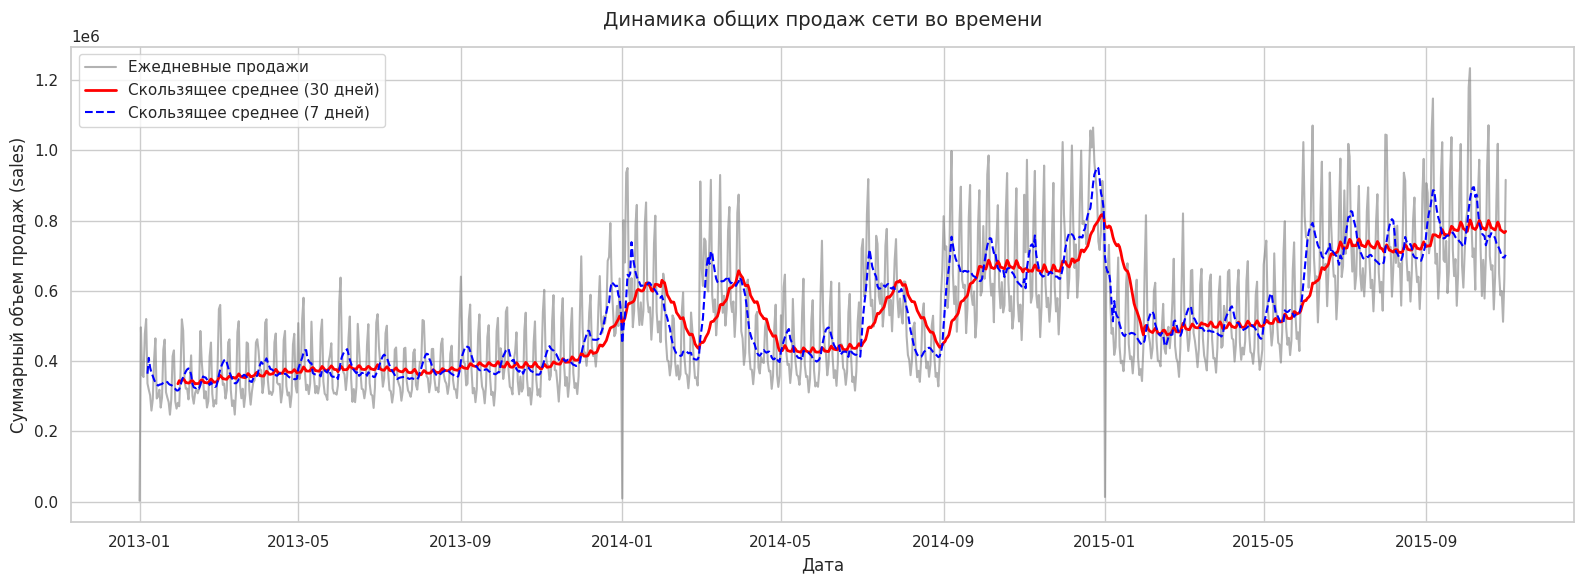

In [86]:
sns.set_theme(style="whitegrid")

daily_sales = base.groupby('date')['sales'].sum().reset_index()

daily_sales['rolling_7d'] = daily_sales['sales'].rolling(window=7).mean()
daily_sales['rolling_30d'] = daily_sales['sales'].rolling(window=30).mean()

plt.figure(figsize=(16, 6))

plt.plot(daily_sales['date'], daily_sales['sales'], 
         alpha=0.6, color='gray', label='Ежедневные продажи')

plt.plot(daily_sales['date'], daily_sales['rolling_30d'], 
         color='red', linewidth=2, label='Скользящее среднее (30 дней)')

plt.plot(daily_sales['date'], daily_sales['rolling_7d'], 
         color='blue', linewidth=1.5, linestyle='--', label='Скользящее среднее (7 дней)')

plt.title('Динамика общих продаж сети во времени', fontsize=14, pad=15)
plt.xlabel('Дата', fontsize=12)
plt.ylabel('Суммарный объем продаж (sales)', fontsize=12)
plt.legend(loc='upper left')
plt.tight_layout()
plt.show()

### Таблица holidays_events

In [14]:
holidays_events.info()

<class 'pandas.DataFrame'>
RangeIndex: 350 entries, 0 to 349
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   date         350 non-null    datetime64[us]
 1   type         350 non-null    str           
 2   locale       350 non-null    str           
 3   locale_name  350 non-null    str           
 4   description  350 non-null    str           
 5   transferred  350 non-null    bool          
dtypes: bool(1), datetime64[us](1), str(4)
memory usage: 14.1 KB


#### Проверка на пропуски

Функция info() показала, что пропусков в таблице нет

#### Проверка на дубликаты

In [50]:
holidays_events.duplicated().sum()

np.int64(0)

Проверка осуществялась на полные дубликаты, так как:
* в одну дату может быть несколько праздников/событий (date)
* так как данный справочник содержит в себе план на праздники и события на несколько лет вперед, описание также повторяется (description)
* остальные данные имеют четкие повторяющиеся категории

In [15]:
holidays_events.describe(include='all')

,date,type,locale,locale_name,description,transferred
count,350,350,350,350,350,350
unique,NaN,6,3,24,103,2
top,NaN,Holiday,National,Ecuador,Carnaval,False
freq,NaN,221,174,174,10,338
mean,2015-04-24 00:45:15.428571,NaN,NaN,NaN,NaN,NaN
min,2012-03-02 00:00:00,NaN,NaN,NaN,NaN,NaN
25%,2013-12-23 06:00:00,NaN,NaN,NaN,NaN,NaN
50%,2015-06-08 00:00:00,NaN,NaN,NaN,NaN,NaN
75%,2016-07-03 00:00:00,NaN,NaN,NaN,NaN,NaN
max,2017-12-26 00:00:00,NaN,NaN,NaN,NaN,NaN


In [69]:
holidays_events[holidays_events['description'].str.contains('Terremoto Manabi')]


,date,type,locale,locale_name,description,transferred
219,2016-04-16,Event,National,Ecuador,Terremoto Manabi,False
220,2016-04-17,Event,National,Ecuador,Terremoto Manabi+1,False
221,2016-04-18,Event,National,Ecuador,Terremoto Manabi+2,False
222,2016-04-19,Event,National,Ecuador,Terremoto Manabi+3,False
223,2016-04-20,Event,National,Ecuador,Terremoto Manabi+4,False
225,2016-04-21,Event,National,Ecuador,Terremoto Manabi+5,False
226,2016-04-22,Event,National,Ecuador,Terremoto Manabi+6,False
227,2016-04-23,Event,National,Ecuador,Terremoto Manabi+7,False
228,2016-04-24,Event,National,Ecuador,Terremoto Manabi+8,False
229,2016-04-25,Event,National,Ecuador,Terremoto Manabi+9,False


#### Проверка на опечатки

##### Признак type

In [52]:
holidays_events['type'].unique()

<StringArray>
['Holiday', 'Transfer', 'Additional', 'Bridge', 'Work Day', 'Event']
Length: 6, dtype: str

##### Признак locale

In [53]:
holidays_events['locale'].unique()

<StringArray>
['Local', 'Regional', 'National']
Length: 3, dtype: str

##### Признак locale_name

In [55]:
sorted(holidays_events['locale_name'].unique())

['Ambato',
 'Cayambe',
 'Cotopaxi',
 'Cuenca',
 'Ecuador',
 'El Carmen',
 'Esmeraldas',
 'Guaranda',
 'Guayaquil',
 'Ibarra',
 'Imbabura',
 'Latacunga',
 'Libertad',
 'Loja',
 'Machala',
 'Manta',
 'Puyo',
 'Quevedo',
 'Quito',
 'Riobamba',
 'Salinas',
 'Santa Elena',
 'Santo Domingo',
 'Santo Domingo de los Tsachilas']

##### Признак description

In [70]:
sorted(holidays_events['description'].unique())

['Batalla De Pichincha',
 'Black Friday',
 'Cantonizacion De Cayambe',
 'Cantonizacion De El Carmen',
 'Cantonizacion De Guaranda',
 'Cantonizacion De Latacunga',
 'Cantonizacion De Libertad',
 'Cantonizacion De Quevedo',
 'Cantonizacion De Riobamba',
 'Cantonizacion De Salinas',
 'Cantonizacion Del Puyo',
 'Carnaval',
 'Cyber Monday',
 'Dia De Difuntos',
 'Dia De La Madre',
 'Dia De La Madre-1',
 'Dia Del Trabajo',
 'Fundacion De Ambato',
 'Fundacion De Cuenca',
 'Fundacion De Esmeraldas',
 'Fundacion De Guayaquil',
 'Fundacion De Guayaquil-1',
 'Fundacion De Ibarra',
 'Fundacion De Loja',
 'Fundacion De Machala',
 'Fundacion De Manta',
 'Fundacion De Quito',
 'Fundacion De Quito-1',
 'Fundacion De Riobamba',
 'Fundacion De Santo Domingo',
 'Inauguracion Mundial De Futbol Brasil',
 'Independencia De Ambato',
 'Independencia De Cuenca',
 'Independencia De Guaranda',
 'Independencia De Guayaquil',
 'Independencia De Latacunga',
 'Mundial De Futbol Brasil: Cuartos De Final',
 'Mundial De

Были обнаружены опечатки: 'Recupero puente Navidad' и  'Recupero Puente Navidad', 'Recupero Puente Primer dia del ano' и 'Recupero puente primer dia del ano'.     
Данные опечатки будут исправлены путем приведения всех описаний к одному регистру.   

Заметим также, что есть праздники/события, рядом с названиями которых есть числа (-1, +1 и тд) - это кол-во дней до или после основного праздника/события.

Также в описании праздников/событий есть особенность. Описание может содержать в себе "Traslado".     
В таком случае необходимо обращать внимание на колонку 'transferred', так как    
праздник с "Traslado" в описании является фактическим днем празднования, а праздник с оригинальным названием - календарным праздником, у которого в колонке 'transferred' будет стоять True.

### Признак transffered

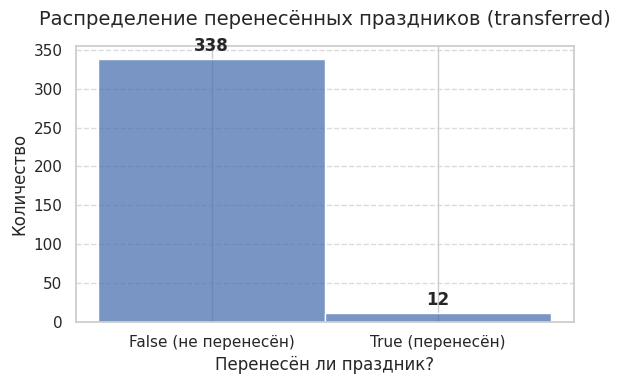

In [64]:
plt.figure(figsize=(6, 4))

ax = sns.histplot(holidays_events['transferred'].apply(lambda x: 'True' if x is True else 'False'))

for container in ax.containers:
    ax.bar_label(container, fmt='%.0f', padding=3, fontsize=12, fontweight='bold')

plt.title('Распределение перенесённых праздников (transferred)', fontsize=14, pad=15)
plt.xlabel('Перенесён ли праздник?', fontsize=12)
plt.ylabel('Количество', fontsize=12)
plt.xticks([0, 1], ['False (не перенесён)', 'True (перенесён)'])
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

### Таблица oil

In [7]:
oil.info()

<class 'pandas.DataFrame'>
RangeIndex: 1218 entries, 0 to 1217
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   date        1218 non-null   datetime64[us]
 1   dcoilwtico  1175 non-null   float64       
dtypes: datetime64[us](1), float64(1)
memory usage: 19.2 KB


#### Проверка на пропуски

Выше видим, что в данных есть пропуски, проверим, в какие дни недели есть пропуски

In [8]:
missing_oil = oil[oil['dcoilwtico'].isna()].copy()

missing_oil['day_of_week'] = missing_oil['date'].dt.day_name()

print(missing_oil['day_of_week'].value_counts())

day_of_week
Monday       23
Friday        9
Thursday      7
Tuesday       2
Wednesday     2
Name: count, dtype: int64


Заметим, что пропуски только в рабочие дни, хотя биржа не работает по выходным.

Крч надо проверить что это были за даты, чекнуть были ли это праздники. ТАКЖЕ ВОПРОС про обрезание дат

In [9]:
oil.describe(include='all')

,date,dcoilwtico
count,1218,1175.000000
mean,2015-05-02 12:00:00,67.714366
min,2013-01-01 00:00:00,26.190000
25%,2014-03-03 06:00:00,46.405000
50%,2015-05-02 12:00:00,53.190000
75%,2016-06-30 18:00:00,95.660000
max,2017-08-31 00:00:00,110.620000
std,NaN,25.630476


#### Проверка на дубликаты

In [73]:
oil.duplicated().sum()

np.int64(0)

Дубликатов нет

### Таблица stores

In [10]:
stores.info()

<class 'pandas.DataFrame'>
RangeIndex: 54 entries, 0 to 53
Data columns (total 5 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   store_nbr  54 non-null     int64
 1   city       54 non-null     str  
 2   state      54 non-null     str  
 3   type       54 non-null     str  
 4   cluster    54 non-null     int64
dtypes: int64(2), str(3)
memory usage: 2.2 KB


#### Наличие пропусков

Таблица выше показала, что пропусков нет.

In [11]:
stores.describe(include='all')

,store_nbr,city,state,type,cluster
count,54.000000,54,54,54,54.000000
unique,NaN,22,16,5,NaN
top,NaN,Quito,Pichincha,D,NaN
freq,NaN,18,19,18,NaN
mean,27.500000,NaN,NaN,NaN,8.481481
std,15.732133,NaN,NaN,NaN,4.693395
min,1.000000,NaN,NaN,NaN,1.000000
25%,14.250000,NaN,NaN,NaN,4.000000
50%,27.500000,NaN,NaN,NaN,8.500000
75%,40.750000,NaN,NaN,NaN,13.000000


#### Наличие дубликатов

In [ ]:
stores.duplicated().sum()

np.int64(0)

Дубликатов нет

#### Проверка на опечатки

#### Признак city

In [76]:
sorted(stores['city'].unique())

['Ambato',
 'Babahoyo',
 'Cayambe',
 'Cuenca',
 'Daule',
 'El Carmen',
 'Esmeraldas',
 'Guaranda',
 'Guayaquil',
 'Ibarra',
 'Latacunga',
 'Libertad',
 'Loja',
 'Machala',
 'Manta',
 'Playas',
 'Puyo',
 'Quevedo',
 'Quito',
 'Riobamba',
 'Salinas',
 'Santo Domingo']

опечаток нет

#### Признак state

In [77]:
sorted(stores['state'].unique())

['Azuay',
 'Bolivar',
 'Chimborazo',
 'Cotopaxi',
 'El Oro',
 'Esmeraldas',
 'Guayas',
 'Imbabura',
 'Loja',
 'Los Rios',
 'Manabi',
 'Pastaza',
 'Pichincha',
 'Santa Elena',
 'Santo Domingo de los Tsachilas',
 'Tungurahua']

опечаток нет

#### Признак type

In [79]:
sorted(stores['type'].unique())

['A', 'B', 'C', 'D', 'E']

Опечаток нет.    
Тип магазина вероятно привязан к классификации уровня доходов населения. 

#### Признак cluster

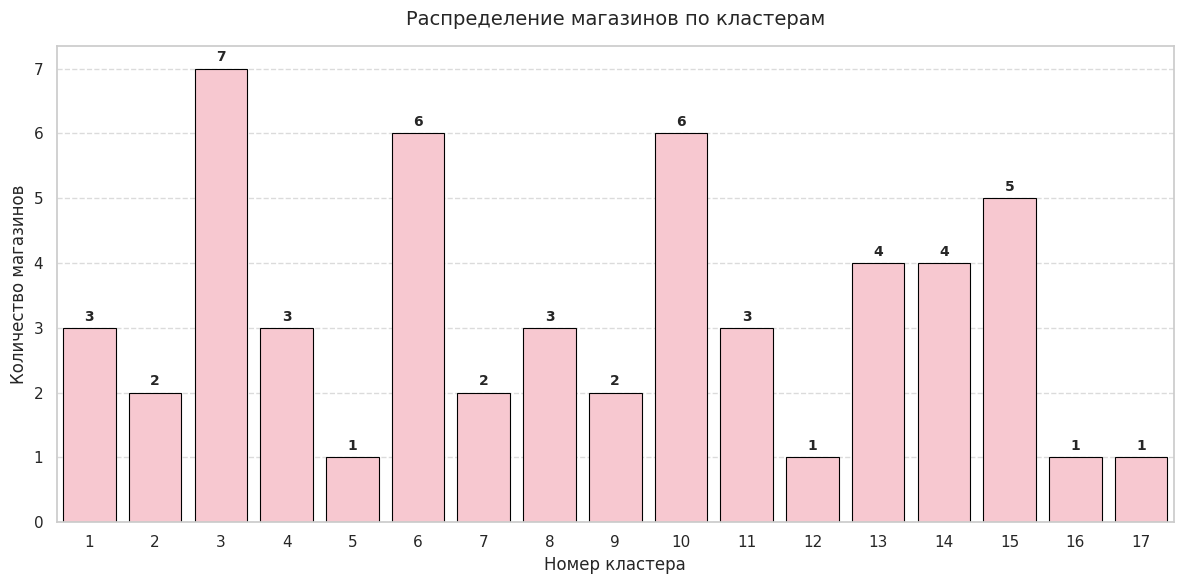

In [82]:
plt.figure(figsize=(12, 6))

ax = sns.countplot(
    data=stores, 
    x='cluster',
    color='pink',
    edgecolor='black',
    linewidth=0.8
)

for container in ax.containers:
    ax.bar_label(container, fmt='%.0f', padding=3, fontsize=10, fontweight='bold')

plt.title('Распределение магазинов по кластерам', fontsize=14, pad=15)
plt.xlabel('Номер кластера', fontsize=12)
plt.ylabel('Количество магазинов', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

Большинство магазинов находятся в кластерах: 3, 6, 10.   
Меньшинство: 5, 12, 16, 17.

### Таблица transactions

In [12]:
transactions.info()

<class 'pandas.DataFrame'>
RangeIndex: 83488 entries, 0 to 83487
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   date          83488 non-null  datetime64[us]
 1   store_nbr     83488 non-null  int64         
 2   transactions  83488 non-null  int64         
dtypes: datetime64[us](1), int64(2)
memory usage: 1.9 MB


#### Наличие пропусков

пропуски отсутсвуют, что следует из таблицы выше

#### Наличие дубликатов

In [ ]:
transactions[['date', 'store_nbr']].duplicated().sum()

np.int64(0)

Дубликатов нет. Использовался такой составной ключ, так как транзакции должны отражать число покупок в каждом магазине за определенную дату

#### Описание данных

In [13]:
transactions.describe(include='all')

,date,store_nbr,transactions
count,83488,83488.000000,83488.000000
mean,2015-05-20 16:07:40.866232,26.939237,1694.602158
min,2013-01-01 00:00:00,1.000000,5.000000
25%,2014-03-27 00:00:00,13.000000,1046.000000
50%,2015-06-08 00:00:00,27.000000,1393.000000
75%,2016-07-14 06:00:00,40.000000,2079.000000
max,2017-08-15 00:00:00,54.000000,8359.000000
std,NaN,15.608204,963.286644


для генерации новых признако: признак о том, что недавно было экстремальное событие (всплеск)? типо после него ожидается плавный спад, когда нужно закупать больше, чем обычно?

очитска признако в пайплайне: уменьшение регистра описания в праздниках. 

что нам делать с другими таблицами, которые также содержат в себе даты???? как и когда их делить? как работать с праздниками/событиями (особенно с землетрясением) и ценами на нефть? 